**Project 1**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. تحميل البيانات
wine = load_wine(as_frame=True)
df = wine.frame
X = wine.data
y = wine.target

# 2. فحص البيانات (عدد العينات، الخصائص، الفئات، والقيم المفقودة)
print(f"عدد العينات (Samples): {X.shape[0]}")
print(f"عدد الخصائص (Features): {X.shape[1]}")
print(f"أسماء الفئات (Target Classes): {wine.target_names}")
print(f"\nإجمالي القيم المفقودة: {df.isnull().sum().sum()}")

print("\nتوزيع الفئات (Class Distribution):")
class_counts = y.value_counts().sort_index()
for idx, count in class_counts.items():
    print(f"Class {idx} ({wine.target_names[idx]}): {count} samples ({count/len(y):.1%})")

عدد العينات (Samples): 178
عدد الخصائص (Features): 13
أسماء الفئات (Target Classes): ['class_0' 'class_1' 'class_2']

إجمالي القيم المفقودة: 0

توزيع الفئات (Class Distribution):
Class 0 (class_0): 59 samples (33.1%)
Class 1 (class_1): 71 samples (39.9%)
Class 2 (class_2): 48 samples (27.0%)


In [2]:
# 3. تقسيم البيانات: أولاً 60% تدريب و 40% مؤقت (للتحقق والاختبار)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=42
)

# تقسيم الـ 40% المؤقتة بالتساوي: 20% تحقق (Validation) و 20% اختبار (Test)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

print(f"Train size: {X_train.shape[0]} | Val size: {X_val.shape[0]} | Test size: {X_test.shape[0]}")

# 4. توحيد المقاييس (Feature Scaling) على بيانات التدريب فقط
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

Train size: 106 | Val size: 36 | Test size: 36


In [3]:
# 5 & 6. تعريف النماذج (Baseline + 6 Experiments)
models = {
    "Baseline (Most Frequent)": DummyClassifier(strategy="most_frequent", random_state=42),
    "KNN (n_neighbors=3)": KNeighborsClassifier(n_neighbors=3),
    "KNN (n_neighbors=5)": KNeighborsClassifier(n_neighbors=5),
    "KNN (n_neighbors=11)": KNeighborsClassifier(n_neighbors=11),
    "SVM (C=0.1, kernel=rbf)": SVC(C=0.1, kernel="rbf", random_state=42),
    "SVM (C=1, kernel=rbf)": SVC(C=1, kernel="rbf", random_state=42),
    "SVM (C=10, kernel=rbf)": SVC(C=10, kernel="rbf", random_state=42),
}

# 7. تدريب النماذج وتقييمها على Validation Set
results = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_val_pred = model.predict(X_val_scaled)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_val_pred),
        "Macro Precision": precision_score(y_val, y_val_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_val, y_val_pred, average="macro", zero_division=0),
        "Macro F1-score": f1_score(y_val, y_val_pred, average="macro", zero_division=0)
    })

results_df = pd.DataFrame(results)
print("\n--- جدول مقارنة التجارب على بيانات التحقق (Validation Results) ---")
display(results_df.round(4))


--- جدول مقارنة التجارب على بيانات التحقق (Validation Results) ---


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-score
0,Baseline (Most Frequent),0.3889,0.1296,0.3333,0.1867
1,KNN (n_neighbors=3),0.8889,0.9030,0.9048,0.8915
2,KNN (n_neighbors=5),0.9444,0.9441,0.9524,0.9452
3,KNN (n_neighbors=11),0.9444,0.9441,0.9524,0.9452
4,"SVM (C=0.1, kernel=rbf)",0.9444,0.9583,0.9389,0.9457
5,"SVM (C=1, kernel=rbf)",1.0000,1.0000,1.0000,1.0000
6,"SVM (C=10, kernel=rbf)",1.0000,1.0000,1.0000,1.0000


النموذج المختار: SVM (C=1, kernel=rbf) (Validation Macro F1 = 1.0000)

--- نتائج الاختبار النهائية (Final Test Metrics) ---
Test Accuracy: 0.9722
Test Macro Precision: 0.9792
Test Macro Recall: 0.9630
Test Macro F1-score: 0.9696


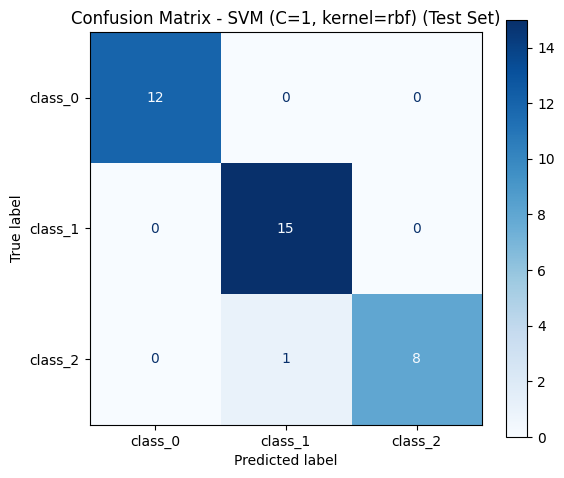

In [4]:
# 8. تحديد النموذج الأفضل بناءً على أعلى Macro F1-score في Validation
best_row = results_df.loc[results_df["Macro F1-score"].idxmax()]
best_model_name = best_row["Model"]
best_model = models[best_model_name]

print(f"النموذج المختار: {best_model_name} (Validation Macro F1 = {best_row['Macro F1-score']:.4f})")

# 9. التقييم النهائي مرة واحدة على بيانات الاختبار (Test Set)
y_test_pred = best_model.predict(X_test_scaled)

test_metrics = {
    "Test Accuracy": accuracy_score(y_test, y_test_pred),
    "Test Macro Precision": precision_score(y_test, y_test_pred, average="macro"),
    "Test Macro Recall": recall_score(y_test, y_test_pred, average="macro"),
    "Test Macro F1-score": f1_score(y_test, y_test_pred, average="macro")
}

print("\n--- نتائج الاختبار النهائية (Final Test Metrics) ---")
for metric, val in test_metrics.items():
    print(f"{metric}: {val:.4f}")

# 10. عرض مصفوفة الارتباك (Confusion Matrix)
cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=wine.target_names)

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap="Blues", ax=ax)
plt.title(f"Confusion Matrix - {best_model_name} (Test Set)")
plt.tight_layout()
plt.show()

**Project 2**

عدد الصفوف (المناطق السكنية / Census Block Groups): 20640
عدد الأعمدة: 9

القيم المفقودة في كل عمود:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

إحصائيات الهدف (MedHouseVal - مقاس بوحدة $100,000):
count    20640.000000
mean         2.068558
std          1.153956
min          0.149990
25%          1.196000
50%          1.797000
75%          2.647250
max          5.000010
Name: MedHouseVal, dtype: float64

Train: 12384 | Val: 4128 | Test: 4128

--- جدول مقارنة تجارب العقارات (Validation Results) ---


,Model,MAE,RMSE,R2
0,Baseline (Mean),0.9039,1.1425,-0.0001
1,Ridge (alpha=0.1),0.5336,0.7298,0.5920
2,Ridge (alpha=1),0.5336,0.7298,0.5920
3,Ridge (alpha=10),0.5336,0.7297,0.5921
4,Random Forest (max_depth=5),0.4972,0.6813,0.6444
5,Random Forest (max_depth=10),0.3764,0.5503,0.7680
6,Random Forest (max_depth=None),0.3410,0.5163,0.7958



النموذج المختار: Random Forest (max_depth=None) (Validation RMSE = 0.5163)

--- نتائج الاختبار النهائية (Final Test Metrics) ---
Test MAE: 0.3428 (ما يعادل $34,284)
Test RMSE: 0.5235 (ما يعادل $52,346)
Test R2: 0.8002


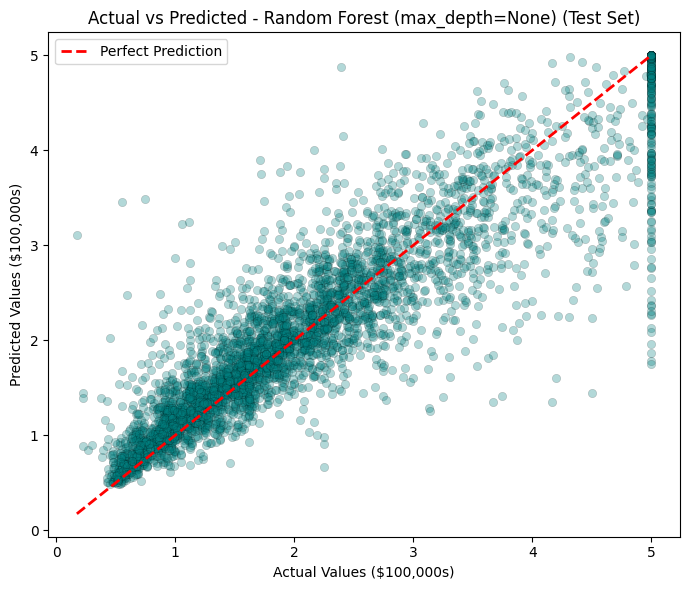


--- أكبر 5 أخطاء في التوقع (Top 5 Largest Absolute Errors) ---


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Actual,Predicted,Abs_Error
12069,4.2386,6.0,7.7231,1.1692,228.0,3.5077,33.83,-117.55,5.0,1.7495,3.2505
13766,3.0625,34.0,3.2143,0.7857,39.0,2.7857,34.08,-117.08,5.0,1.7850,3.2150
6688,0.4999,28.0,7.6774,1.8710,142.0,4.5806,34.15,-118.08,5.0,1.8691,3.1309
19542,1.7679,39.0,5.0000,0.8889,22.0,2.4444,37.63,-120.92,4.5,1.4477,3.0523
15297,3.9750,22.0,6.8964,1.5803,580.0,3.0052,33.16,-117.35,5.0,1.9611,3.0389


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# 1. تحميل البيانات وحفظها كملف CSV
cal = fetch_california_housing(as_frame=True)
housing_df = cal.frame
housing_df.to_csv("california_housing.csv", index=False)

# 2. فحص البيانات والقيم المفقودة وتوزيع الهدف (Tasks 1 & 2)
print(f"عدد الصفوف (المناطق السكنية / Census Block Groups): {housing_df.shape[0]}")
print(f"عدد الأعمدة: {housing_df.shape[1]}")
print("\nالقيم المفقودة في كل عمود:")
print(housing_df.isnull().sum())

target_col = "MedHouseVal"
print(f"\nإحصائيات الهدف ({target_col} - مقاس بوحدة $100,000):")
print(housing_df[target_col].describe())

# فصل الخصائص عن الهدف
X_h = housing_df.drop(columns=[target_col])
y_h = housing_df[target_col]

# 3. تقسيم البيانات: 60% تدريب، 20% تحقق، 20% اختبار (Task 3)
X_h_train, X_h_temp, y_h_train, y_h_temp = train_test_split(
    X_h, y_h, test_size=0.40, random_state=42
)
X_h_val, X_h_test, y_h_val, y_h_test = train_test_split(
    X_h_temp, y_h_temp, test_size=0.50, random_state=42
)

print(f"\nTrain: {len(X_h_train)} | Val: {len(X_h_val)} | Test: {len(X_h_test)}")

# 4 & 5. تجهيز البيانات لكل خوارزمية (Fit على التدريب فقط) (Tasks 4 & 5)
num_cols = X_h.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X_h.select_dtypes(include=["object", "category"]).columns.tolist()

# تجهيز خاص لنموذج Ridge (تعويض المفقود + Scaling)
ridge_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

# تجهيز خاص لنموذج Random Forest (تعويض المفقود بدون حاجة لـ Scaling)
rf_preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

# 6. تعريف النماذج (Baseline + 6 Experiments) (Task 6)
reg_models = {
    "Baseline (Mean)": DummyRegressor(strategy="mean"),
    "Ridge (alpha=0.1)": Pipeline([("prep", ridge_preprocessor), ("model", Ridge(alpha=0.1, random_state=42))]),
    "Ridge (alpha=1)": Pipeline([("prep", ridge_preprocessor), ("model", Ridge(alpha=1.0, random_state=42))]),
    "Ridge (alpha=10)": Pipeline([("prep", ridge_preprocessor), ("model", Ridge(alpha=10.0, random_state=42))]),
    "Random Forest (max_depth=5)": Pipeline([("prep", rf_preprocessor), ("model", RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1))]),
    "Random Forest (max_depth=10)": Pipeline([("prep", rf_preprocessor), ("model", RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1))]),
    "Random Forest (max_depth=None)": Pipeline([("prep", rf_preprocessor), ("model", RandomForestRegressor(n_estimators=100, max_depth=None, random_state=42, n_jobs=-1))]),
}

# 7. التقييم على Validation Set (Task 7)
reg_results = []
for name, model in reg_models.items():
    model.fit(X_h_train, y_h_train)
    y_h_val_pred = model.predict(X_h_val)

    reg_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_h_val, y_h_val_pred),
        "RMSE": root_mean_squared_error(y_h_val, y_h_val_pred),
        "R2": r2_score(y_h_val, y_h_val_pred)
    })

reg_results_df = pd.DataFrame(reg_results)
print("\n--- جدول مقارنة تجارب العقارات (Validation Results) ---")
display(reg_results_df.round(4))

# 8. اختيار النموذج صاحب أقل RMSE في Validation (Task 8)
best_reg_row = reg_results_df.loc[reg_results_df["RMSE"].idxmin()]
best_reg_name = best_reg_row["Model"]
best_reg_model = reg_models[best_reg_name]

print(f"\nالنموذج المختار: {best_reg_name} (Validation RMSE = {best_reg_row['RMSE']:.4f})")

# 9. التقييم النهائي مرة واحدة على Test Set (Task 9)
y_h_test_pred = best_reg_model.predict(X_h_test)

test_mae = mean_absolute_error(y_h_test, y_h_test_pred)
test_rmse = root_mean_squared_error(y_h_test, y_h_test_pred)
test_r2 = r2_score(y_h_test, y_h_test_pred)

print("\n--- نتائج الاختبار النهائية (Final Test Metrics) ---")
print(f"Test MAE: {test_mae:.4f} (ما يعادل ${test_mae * 100000:,.0f})")
print(f"Test RMSE: {test_rmse:.4f} (ما يعادل ${test_rmse * 100000:,.0f})")
print(f"Test R2: {test_r2:.4f}")

# 10. رسم القيم الحقيقية مقابل المتوقعة وتحليل أكبر 5 أخطاء (Task 10)
plt.figure(figsize=(7, 6))
plt.scatter(y_h_test, y_h_test_pred, alpha=0.3, color="teal", edgecolors="k", linewidth=0.3)
plt.plot([y_h_test.min(), y_h_test.max()], [y_h_test.min(), y_h_test.max()], "r--", lw=2, label="Perfect Prediction")
plt.xlabel("Actual Values ($100,000s)")
plt.ylabel("Predicted Values ($100,000s)")
plt.title(f"Actual vs Predicted - {best_reg_name} (Test Set)")
plt.legend()
plt.tight_layout()
plt.show()

# تحليل أكبر 5 أخطاء مطلقة (Largest 5 Absolute Errors)
error_df = X_h_test.copy()
error_df["Actual"] = y_h_test
error_df["Predicted"] = y_h_test_pred
error_df["Abs_Error"] = np.abs(error_df["Actual"] - error_df["Predicted"])

print("\n--- أكبر 5 أخطاء في التوقع (Top 5 Largest Absolute Errors) ---")
display(error_df.sort_values(by="Abs_Error", ascending=False).head(5).round(4))

In [6]:
# تحديد الأعمدة الرقمية والنصية تلقائياً
num_cols = X_h.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X_h.select_dtypes(include=["object", "category"]).columns.tolist()

# تجهيز خاص لنموذج Ridge (تعويض المفقود + Scaling)
ridge_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

# تجهيز خاص لنموذج Random Forest (تعويض المفقود بدون حاجة لـ Scaling)
rf_preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

# 4 & 6. تعريف النماذج (Baseline + 6 Experiments)
reg_models = {
    "Baseline (Mean)": DummyRegressor(strategy="mean"),
    "Ridge (alpha=0.1)": Pipeline([("prep", ridge_preprocessor), ("model", Ridge(alpha=0.1, random_state=42))]),
    "Ridge (alpha=1)": Pipeline([("prep", ridge_preprocessor), ("model", Ridge(alpha=1.0, random_state=42))]),
    "Ridge (alpha=10)": Pipeline([("prep", ridge_preprocessor), ("model", Ridge(alpha=10.0, random_state=42))]),
    "Random Forest (max_depth=5)": Pipeline([("prep", rf_preprocessor), ("model", RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1))]),
    "Random Forest (max_depth=10)": Pipeline([("prep", rf_preprocessor), ("model", RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1))]),
    "Random Forest (max_depth=None)": Pipeline([("prep", rf_preprocessor), ("model", RandomForestRegressor(n_estimators=100, max_depth=None, random_state=42, n_jobs=-1))]),
}

# 7. التقييم على Validation Set
reg_results = []
for name, model in reg_models.items():
    model.fit(X_h_train, y_h_train)
    y_h_val_pred = model.predict(X_h_val)

    reg_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_h_val, y_h_val_pred),
        "RMSE": root_mean_squared_error(y_h_val, y_h_val_pred),
        "R2": r2_score(y_h_val, y_h_val_pred)
    })

reg_results_df = pd.DataFrame(reg_results)
print("\n--- جدول مقارنة تجارب العقارات (Validation Results) ---")
display(reg_results_df.round(4))


--- جدول مقارنة تجارب العقارات (Validation Results) ---


,Model,MAE,RMSE,R2
0,Baseline (Mean),0.9039,1.1425,-0.0001
1,Ridge (alpha=0.1),0.5336,0.7298,0.5920
2,Ridge (alpha=1),0.5336,0.7298,0.5920
3,Ridge (alpha=10),0.5336,0.7297,0.5921
4,Random Forest (max_depth=5),0.4972,0.6813,0.6444
5,Random Forest (max_depth=10),0.3764,0.5503,0.7680
6,Random Forest (max_depth=None),0.3410,0.5163,0.7958


النموذج المختار: Random Forest (max_depth=None) (Validation RMSE = 0.5163)

--- نتائج الاختبار النهائية (Final Test Metrics) ---
Test MAE: 0.3428
Test RMSE: 0.5235
Test R2: 0.8002


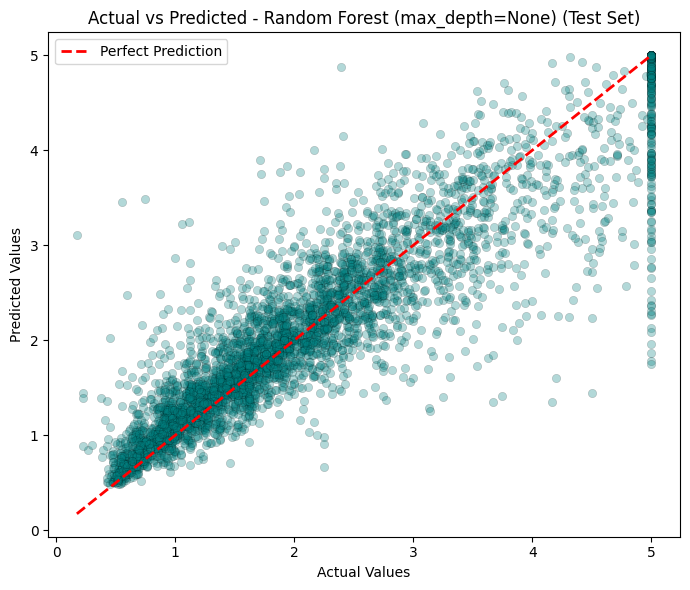


--- أكبر 5 أخطاء في التوقع (Top 5 Largest Absolute Errors) ---


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Actual,Predicted,Abs_Error
12069,4.2386,6.0,7.723077,1.169231,228.0,3.507692,33.83,-117.55,5.00001,1.749490,3.250520
13766,3.0625,34.0,3.214286,0.785714,39.0,2.785714,34.08,-117.08,5.00001,1.785041,3.214969
6688,0.4999,28.0,7.677419,1.870968,142.0,4.580645,34.15,-118.08,5.00001,1.869070,3.130940
19542,1.7679,39.0,5.000000,0.888889,22.0,2.444444,37.63,-120.92,4.50000,1.447720,3.052280
15297,3.9750,22.0,6.896373,1.580311,580.0,3.005181,33.16,-117.35,5.00001,1.961140,3.038870


In [7]:
# 8. اختيار النموذج صاحب أقل RMSE في Validation
best_reg_row = reg_results_df.loc[reg_results_df["RMSE"].idxmin()]
best_reg_name = best_reg_row["Model"]
best_reg_model = reg_models[best_reg_name]

print(f"النموذج المختار: {best_reg_name} (Validation RMSE = {best_reg_row['RMSE']:.4f})")

# 9. التقييم النهائي مرة واحدة على Test Set
y_h_test_pred = best_reg_model.predict(X_h_test)

test_mae = mean_absolute_error(y_h_test, y_h_test_pred)
test_rmse = root_mean_squared_error(y_h_test, y_h_test_pred)
test_r2 = r2_score(y_h_test, y_h_test_pred)

print("\n--- نتائج الاختبار النهائية (Final Test Metrics) ---")
print(f"Test MAE: {test_mae:.4f}")
print(f"Test RMSE: {test_rmse:.4f}")
print(f"Test R2: {test_r2:.4f}")

# 10. رسم القيم الحقيقية مقابل المتوقعة
plt.figure(figsize=(7, 6))
plt.scatter(y_h_test, y_h_test_pred, alpha=0.3, color="teal", edgecolors="k", linewidth=0.3)
plt.plot([y_h_test.min(), y_h_test.max()], [y_h_test.min(), y_h_test.max()], "r--", lw=2, label="Perfect Prediction")
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title(f"Actual vs Predicted - {best_reg_name} (Test Set)")
plt.legend()
plt.tight_layout()
plt.show()

# تحليل أكبر 5 أخطاء مطلقة (Largest 5 Absolute Errors)
error_df = X_h_test.copy()
error_df["Actual"] = y_h_test
error_df["Predicted"] = y_h_test_pred
error_df["Abs_Error"] = np.abs(error_df["Actual"] - error_df["Predicted"])

print("\n--- أكبر 5 أخطاء في التوقع (Top 5 Largest Absolute Errors) ---")
display(error_df.sort_values(by="Abs_Error", ascending=False).head(5))

**Project 3**

عدد العملاء: 440 | عدد الأعمدة: 8
القيم المفقودة: 0

ملخص إحصائي للإنفاق السنوي (الأصلي):


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.00,440.00,440.00,440.00,440.00,440.00
mean,12000.30,5796.27,7951.28,3071.93,2881.49,1524.87
std,12647.33,7380.38,9503.16,4854.67,4767.85,2820.11
min,3.00,55.00,3.00,25.00,3.00,3.00
25%,3127.75,1533.00,2153.00,742.25,256.75,408.25
50%,8504.00,3627.00,4755.50,1526.00,816.50,965.50
75%,16933.75,7190.25,10655.75,3554.25,3922.00,1820.25
max,112151.00,73498.00,92780.00,60869.00,40827.00,47943.00



--- جدول مقارنة تجارب التجميع (Clustering Experiments) ---


,Algorithm,Clusters (k),Silhouette Score,Davies-Bouldin Index
0,K-Means,2,0.2903,1.3515
1,Agglomerative (ward),2,0.2585,1.6004
2,K-Means,3,0.2594,1.3406
3,Agglomerative (ward),3,0.2547,1.5390
4,K-Means,4,0.1885,1.5408
5,Agglomerative (ward),4,0.2021,1.5211
6,K-Means,5,0.1916,1.4843
7,Agglomerative (ward),5,0.2025,1.3862



النموذج المختار: K-Means (k=2)
Silhouette Score: 0.2903 | Davies-Bouldin Index: 1.3515

--- حجم كل شريحة (Cluster Sizes) ---
Cluster
0    252
1    188
Name: count, dtype: int64

--- متوسط الإنفاق السنوي لكل شريحة (Mean Spending - Original Values) ---


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,13973.13,2401.75,2918.71,3705.67,491.94,1038.04
1,9355.87,10346.36,14697.06,2222.45,6084.51,2177.43



--- وسيط الإنفاق السنوي لكل شريحة (Median Spending - Original Values) ---


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,10347.5,1871.0,2406.0,2225.0,327.5,749.5
1,5406.5,7690.5,11527.0,1061.5,4495.0,1388.5



--- توزيع Channel و Region داخل كل شريحة (للوصف فقط) ---


Channel,1,2
Cluster,,
0,244,8
1,54,134


Region,1,2,3
Cluster,,,
0,48,28,176
1,29,19,140


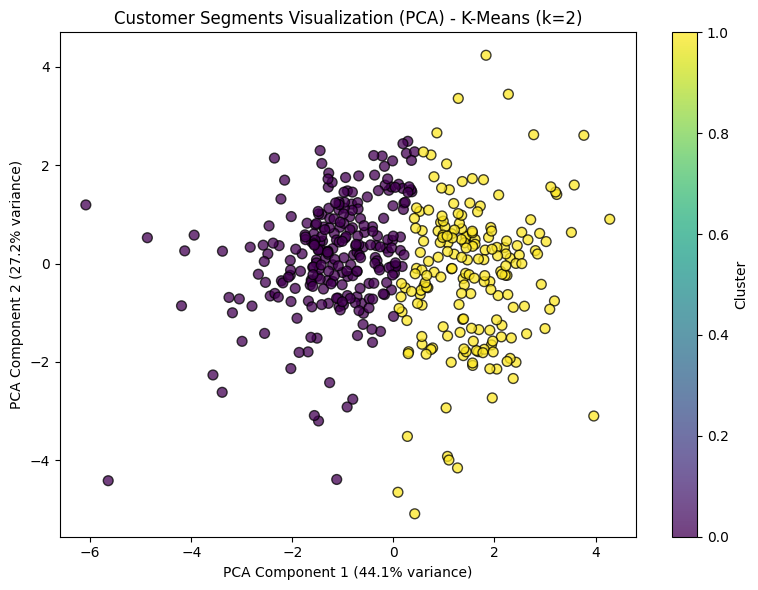

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA

# 1. تحميل البيانات وحفظها كملف CSV محلي
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00292/Wholesale%20customers%20data.csv"
wholesale_df = pd.read_csv(url)
wholesale_df.to_csv("wholesale_customers.csv", index=False)

# فحص البيانات والإنفاق والقيم الشاذة (Task 1)
spending_cols = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
print(f"عدد العملاء: {wholesale_df.shape[0]} | عدد الأعمدة: {wholesale_df.shape[1]}")
print(f"القيم المفقودة: {wholesale_df.isnull().sum().sum()}")
print("\nملخص إحصائي للإنفاق السنوي (الأصلي):")
display(wholesale_df[spending_cols].describe().round(2))

# استبعاد Channel و Region من التجميع (Clustering)
X_ws = wholesale_df[spending_cols].copy()

# 2. تطبيق log1p ثم StandardScaler (Task 2)
X_ws_log = np.log1p(X_ws)
scaler_ws = StandardScaler()
X_ws_scaled = scaler_ws.fit_transform(X_ws_log)

# 3 & 4. تشغيل التجارب الثمانية وحساب Silhouette و Davies-Bouldin قبل PCA (Tasks 3 & 4)
cluster_results = []
cluster_models = {}

for k in [2, 3, 4, 5]:
    # K-Means
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km_labels = km.fit_predict(X_ws_scaled)
    cluster_models[f"K-Means (k={k})"] = km_labels
    cluster_results.append({
        "Algorithm": "K-Means",
        "Clusters (k)": k,
        "Silhouette Score": silhouette_score(X_ws_scaled, km_labels),
        "Davies-Bouldin Index": davies_bouldin_score(X_ws_scaled, km_labels)
    })

    # Agglomerative Clustering
    agg = AgglomerativeClustering(n_clusters=k, linkage="ward")
    agg_labels = agg.fit_predict(X_ws_scaled)
    cluster_models[f"Agglomerative (k={k})"] = agg_labels
    cluster_results.append({
        "Algorithm": "Agglomerative (ward)",
        "Clusters (k)": k,
        "Silhouette Score": silhouette_score(X_ws_scaled, agg_labels),
        "Davies-Bouldin Index": davies_bouldin_score(X_ws_scaled, agg_labels)
    })

cluster_results_df = pd.DataFrame(cluster_results)
print("\n--- جدول مقارنة تجارب التجميع (Clustering Experiments) ---")
display(cluster_results_df.round(4))

# 5. اختيار النموذج الأفضل (أعلى Silhouette، وعند التعادل أقل Davies-Bouldin) (Task 5)
best_ws_row = cluster_results_df.sort_values(
    by=["Silhouette Score", "Davies-Bouldin Index"], ascending=[False, True]
).iloc[0]

best_ws_key = f"{'K-Means' if best_ws_row['Algorithm'] == 'K-Means' else 'Agglomerative'} (k={int(best_ws_row['Clusters (k)'])})"
best_labels = cluster_models[best_ws_key]

print(f"\nالنموذج المختار: {best_ws_key}")
print(f"Silhouette Score: {best_ws_row['Silhouette Score']:.4f} | Davies-Bouldin Index: {best_ws_row['Davies-Bouldin Index']:.4f}")

# 6 & 7. حجم كل مجموعة ومتوسط/وسيط الإنفاق بالقيم الأصلية (Tasks 6 & 7)
wholesale_df["Cluster"] = best_labels

print("\n--- حجم كل شريحة (Cluster Sizes) ---")
print(wholesale_df["Cluster"].value_counts().sort_index())

print("\n--- متوسط الإنفاق السنوي لكل شريحة (Mean Spending - Original Values) ---")
display(wholesale_df.groupby("Cluster")[spending_cols].mean().round(2))

print("\n--- وسيط الإنفاق السنوي لكل شريحة (Median Spending - Original Values) ---")
display(wholesale_df.groupby("Cluster")[spending_cols].median().round(2))

print("\n--- توزيع Channel و Region داخل كل شريحة (للوصف فقط) ---")
display(pd.crosstab(wholesale_df["Cluster"], wholesale_df["Channel"]))
display(pd.crosstab(wholesale_df["Cluster"], wholesale_df["Region"]))

# 10. الرسم ثنائي الأبعاد باستخدام PCA (Task 10)
pca = PCA(n_components=2, random_state=42)
X_ws_pca = pca.fit_transform(X_ws_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_ws_pca[:, 0], X_ws_pca[:, 1], c=best_labels, cmap="viridis", alpha=0.75, edgecolors="k", s=50)
plt.xlabel(f"PCA Component 1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PCA Component 2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.title(f"Customer Segments Visualization (PCA) - {best_ws_key}")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()